<a href="https://colab.research.google.com/github/Rishika12890/E.-coli-Protein-Data-EDA/blob/main/Ecoli_protein_data_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ecoli Dataset - Exploratory Data Analysis (EDA)

This notebook loads and analyzes the Ecoli dataset (`ecoli.data` and `ecoli.names`) to explore numerical protein-sequence measurements and protein localization classes.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import os

# Ensure dataset files are downloaded
urls = {
    '/content/ecoli.names': 'https://archive.ics.uci.edu/ml/machine-learning-databases/ecoli/ecoli.names',
    '/content/ecoli.data': 'https://archive.ics.uci.edu/ml/machine-learning-databases/ecoli/ecoli.data'
}

for path, url in urls.items():
    if not os.path.exists(path):
        print(f"Downloading {url} to {path}...")
        try:
            urllib.request.urlretrieve(url, path)
        except Exception as e:
            print(f"Failed to download from main URL. Trying alternative mirror... Error: {e}")
            # Fallback direct data download
            alternative_url = url.replace('https://archive.ics.uci.edu/ml/machine-learning-databases/', 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/')
            urllib.request.urlretrieve(alternative_url, path)

# Read dataset documentation to inspect structure
with open('/content/ecoli.names', 'r') as f:
    names_content = f.read()
print("=== Ecoli Names Metadata Snippet ===")
print("\n".join(names_content.splitlines()[:25]))

# Column names definition
column_names = ['Sequence_Name', 'mcg', 'gvh', 'lip', 'chg', 'aac', 'alm1', 'alm2', 'Class']

# Load the dataset using raw string for regex separator to avoid escape sequence warnings
df = pd.read_csv('/content/ecoli.data', sep=r'\s+', names=column_names)

# Diagnostic checks
print("\n=== Dataset Head ===")
display(df.head())
print("\n=== Dataset Tail ===")
display(df.tail())
print(f"\nDataset Shape: {df.shape}")
print("\n=== Info ===")
df.info()
print("\n=== Describe ===")
display(df.describe())

=== Ecoli Names Metadata Snippet ===
1. Title: Protein Localization Sites


2. Creator and Maintainer:
	     Kenta Nakai
             Institue of Molecular and Cellular Biology
	     Osaka, University
	     1-3 Yamada-oka, Suita 565 Japan
	     nakai@imcb.osaka-u.ac.jp
             http://www.imcb.osaka-u.ac.jp/nakai/psort.html
   Donor: Paul Horton (paulh@cs.berkeley.edu)
   Date:  September, 1996
   See also: yeast database

3. Past Usage.
Reference: "A Probablistic Classification System for Predicting the Cellular 
           Localization Sites of Proteins", Paul Horton & Kenta Nakai,
           Intelligent Systems in Molecular Biology, 109-115.
	   St. Louis, USA 1996.
Results: 81% for E.coli with an ad hoc structured
	 probability model. Also similar accuracy for Binary Decision Tree and
	 Bayesian Classifier methods applied by the same authors in
	 unpublished results.

Predicted Attribute: Localization site of protein. ( non-numeric ).

=== Dataset Head ===


,Sequence_Name,mcg,gvh,lip,chg,aac,alm1,alm2,Class
0,AAT_ECOLI,0.49,0.29,0.48,0.5,0.56,0.24,0.35,cp
1,ACEA_ECOLI,0.07,0.40,0.48,0.5,0.54,0.35,0.44,cp
2,ACEK_ECOLI,0.56,0.40,0.48,0.5,0.49,0.37,0.46,cp
3,ACKA_ECOLI,0.59,0.49,0.48,0.5,0.52,0.45,0.36,cp
4,ADI_ECOLI,0.23,0.32,0.48,0.5,0.55,0.25,0.35,cp



=== Dataset Tail ===


,Sequence_Name,mcg,gvh,lip,chg,aac,alm1,alm2,Class
331,TREA_ECOLI,0.74,0.56,0.48,0.5,0.47,0.68,0.30,pp
332,UGPB_ECOLI,0.71,0.57,0.48,0.5,0.48,0.35,0.32,pp
333,USHA_ECOLI,0.61,0.60,0.48,0.5,0.44,0.39,0.38,pp
334,XYLF_ECOLI,0.59,0.61,0.48,0.5,0.42,0.42,0.37,pp
335,YTFQ_ECOLI,0.74,0.74,0.48,0.5,0.31,0.53,0.52,pp



Dataset Shape: (336, 9)

=== Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Sequence_Name  336 non-null    object 
 1   mcg            336 non-null    float64
 2   gvh            336 non-null    float64
 3   lip            336 non-null    float64
 4   chg            336 non-null    float64
 5   aac            336 non-null    float64
 6   alm1           336 non-null    float64
 7   alm2           336 non-null    float64
 8   Class          336 non-null    object 
dtypes: float64(7), object(2)
memory usage: 23.8+ KB

=== Describe ===


,mcg,gvh,lip,chg,aac,alm1,alm2
count,336.000000,336.000000,336.000000,336.000000,336.000000,336.000000,336.000000
mean,0.500060,0.500000,0.495476,0.501488,0.500030,0.500179,0.499732
std,0.194634,0.148157,0.088495,0.027277,0.122376,0.215751,0.209411
min,0.000000,0.160000,0.480000,0.500000,0.000000,0.030000,0.000000
25%,0.340000,0.400000,0.480000,0.500000,0.420000,0.330000,0.350000
50%,0.500000,0.470000,0.480000,0.500000,0.495000,0.455000,0.430000
75%,0.662500,0.570000,0.480000,0.500000,0.570000,0.710000,0.710000
max,0.890000,1.000000,1.000000,1.000000,0.880000,1.000000,0.990000


### **Question 1: Count records in each localization class**
We use Pandas `value_counts()` to compute frequencies for each localization class.

In [3]:
class_counts = df['Class'].value_counts()
print("=== Localization Class Counts ===")
print(class_counts)

=== Localization Class Counts ===
Class
cp     143
im      77
pp      52
imU     35
om      20
omL      5
imL      2
imS      2
Name: count, dtype: int64


### **Question 2: Calculate mean, median, minimum, and maximum**
Using NumPy functions, we calculate descriptive statistics for three numeric columns: `mcg`, `gvh`, and `aac`.

In [4]:
for col in ['mcg', 'gvh', 'aac']:
    col_arr = df[col].to_numpy()
    print(f"--- {col} Statistics (using NumPy) ---")
    print(f"Mean:   {np.mean(col_arr):.4f}")
    print(f"Median: {np.median(col_arr):.4f}")
    print(f"Min:    {np.min(col_arr):.4f}")
    print(f"Max:    {np.max(col_arr):.4f}\n")

--- mcg Statistics (using NumPy) ---
Mean:   0.5001
Median: 0.5000
Min:    0.0000
Max:    0.8900

--- gvh Statistics (using NumPy) ---
Mean:   0.5000
Median: 0.4700
Min:    0.1600
Max:    1.0000

--- aac Statistics (using NumPy) ---
Mean:   0.5000
Median: 0.4950
Min:    0.0000
Max:    0.8800



### **Question 3: Which class has the most records?**
We determine the class with the maximum count using Pandas.

In [5]:
most_common_class = class_counts.idxmax()
most_common_count = class_counts.max()
print(f"The localization class with the most records is '{most_common_class}' with {most_common_count} records.")

The localization class with the most records is 'cp' with 143 records.


### **Question 4: Compare average values of two selected numeric columns across classes**
We compare the class-specific mean values of the `mcg` and `gvh` features using a Pandas `groupby` operation.

In [6]:
grouped_comparison = df.groupby('Class')[['mcg', 'gvh']].mean()
display(grouped_comparison)

,mcg,gvh
Class,,
cp,0.363566,0.409720
im,0.478442,0.496623
imL,0.725000,0.470000
imS,0.740000,0.510000
imU,0.726000,0.458857
om,0.672500,0.710000
omL,0.698000,0.512000
pp,0.652115,0.699808


### **Question 5: Find records with the highest values in a selected column**
We sort the dataset descendingly to isolate the 5 records with the highest values for the `mcg` score.

In [7]:
top_mcg_records = df.sort_values(by='mcg', ascending=False).head(5)
display(top_mcg_records)

,Sequence_Name,mcg,gvh,lip,chg,aac,alm1,alm2,Class
186,NHAA_ECOLI,0.89,0.55,0.48,0.5,0.51,0.72,0.76,im
252,SECD_ECOLI,0.88,0.42,0.48,0.5,0.52,0.73,0.75,imU
244,MCP4_ECOLI,0.87,0.49,0.48,0.5,0.61,0.76,0.79,imU
242,MCP1_ECOLI,0.86,0.39,0.48,0.5,0.59,0.89,0.90,imU
255,TYRP_ECOLI,0.86,0.55,0.48,0.5,0.63,0.81,0.83,imU


### **Question 6: Check for missing values and duplicates**
We perform a quality assessment check on the dataset.

In [9]:
print("Missing Values per Column:")
print(df.isnull().sum())
print(f"\nNumber of duplicate rows: {df.duplicated().sum()}")

Missing Values per Column:
Sequence_Name    0
mcg              0
gvh              0
lip              0
chg              0
aac              0
alm1             0
alm2             0
Class            0
dtype: int64

Number of duplicate rows: 0


### **Data Visualizations**
We construct a Class-Count Chart and a Histogram distribution plot.


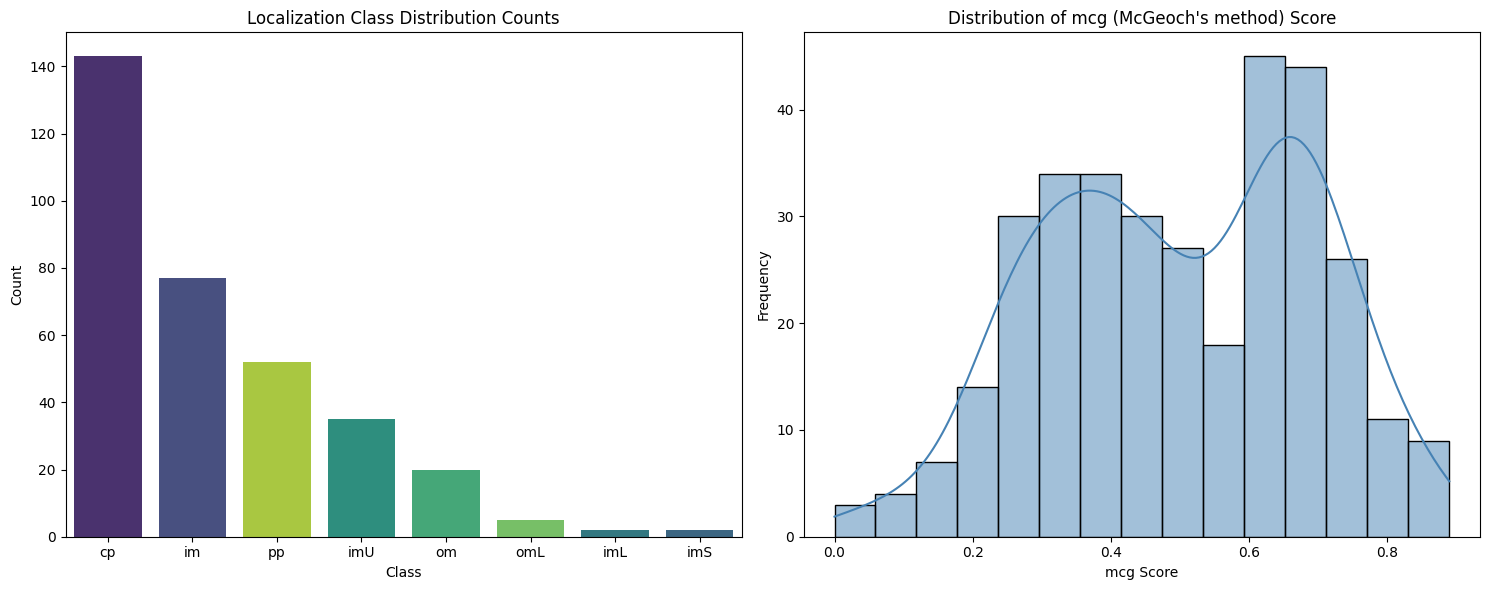

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Class Count Chart
sns.countplot(data=df, x='Class', order=class_counts.index, ax=axes[0], hue='Class', palette='viridis', legend=False)
axes[0].set_title('Localization Class Distribution Counts')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')

# 2. Histogram of mcg Feature
sns.histplot(data=df, x='mcg', bins=15, kde=True, ax=axes[1], color='steelblue')
axes[1].set_title("Distribution of mcg (McGeoch's method) Score")
axes[1].set_xlabel('mcg Score')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()